In [7]:
from pathlib import Path
from decimal import Decimal
import re

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Setup: archives, colors, IEEE-friendly figure appearance
# ------------------------------------------------------------
DATA_DIR = Path('Comparison') if Path('Comparison').is_dir() else Path('.')
OUTPUT_DIR = Path('actor_loss_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LEARNING_RATES = ('0.000001', '0.00001', '0.0001')
NODES = (45, 55, 65)
COLORS = {
    '0.000001': 'navy',
    '0.00001': 'orange',
    '0.0001': 'crimson',
}
WINDOW = 10  # Use 1 for raw averaged loss; 10 for 10-episode moving average.
SAVE_FIGURES = True

plt.rcParams.update({
    'font.family': 'DejaVu Serif',  # Bundled with Matplotlib; no Times New Roman warnings.
    'font.size': 10,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.linewidth': 1.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Accept filenames like ...45_nodes_lr_0_00001.npz, ...45 nodes_lr_0_00001.npz,
# and decimal-dot learning-rate suffixes.
FILE_PATTERN = re.compile(
    r'(?P<nodes>\d+)[ _-]*nodes[ _-]*lr[_-]*(?P<lr>0[_.]\d+)\.npz$',
    re.IGNORECASE,
)
KEY_PATTERN = re.compile(
    r'agent(?P<agent>[12])_actor_loss_lr_(?P<lr>0[_.]\d+)',
    re.IGNORECASE,
)


def as_rate(text):
    return Decimal(text.replace('_', '.'))


# ------------------------------------------------------------
# 2. Read matching actor losses and average the two agents
# ------------------------------------------------------------
averaged_losses = {}  # (nodes, Decimal(learning_rate)) -> per-episode mean

for path in sorted(DATA_DIR.glob('*.npz')):
    match = FILE_PATTERN.search(path.name)
    if not match:
        continue
    nodes = int(match.group('nodes'))
    lr = as_rate(match.group('lr'))
    if nodes not in NODES or lr not in {as_rate(s) for s in LEARNING_RATES}:
        continue

    with np.load(path, allow_pickle=False) as archive:
        agent_losses = {}
        for key in archive.files:
            key_match = KEY_PATTERN.fullmatch(key)
            if not key_match or as_rate(key_match.group('lr')) != lr:
                continue
            agent = int(key_match.group('agent'))
            arr = np.asarray(archive[key], dtype=np.float64)
            if arr.ndim != 1 or arr.size == 0:
                raise ValueError(f'{path.name}: {key} must be a nonempty 1-D array, got {arr.shape}')
            agent_losses[agent] = arr

    if set(agent_losses) != {1, 2}:
        raise KeyError(f'{path.name}: expected matching Agent 1 and Agent 2 actor-loss keys; '
                       f'found agents {sorted(agent_losses)}')
    if agent_losses[1].shape != agent_losses[2].shape:
        raise ValueError(f'{path.name}: Agent losses have unequal episode counts '
                         f'{len(agent_losses[1])} and {len(agent_losses[2])}; '
                         'align episodes before averaging.')
    if not all(np.all(np.isfinite(arr)) for arr in agent_losses.values()):
        raise ValueError(f'{path.name}: actor-loss values contain NaN or infinity.')

    lookup = (nodes, lr)
    if lookup in averaged_losses:
        raise ValueError(f'Duplicate archive for {nodes} nodes, LR={lr}: {path.name}')
    averaged_losses[lookup] = (agent_losses[1] + agent_losses[2]) / 2.0
    print(f'Loaded: {nodes} nodes | LR={lr} | {len(averaged_losses[lookup])} episodes')

missing = [(n, lr) for n in NODES for lr in LEARNING_RATES
           if (n, as_rate(lr)) not in averaged_losses]
if missing:
    raise FileNotFoundError(f'Missing expected node/LR data in {DATA_DIR.resolve()}: {missing}')


# ------------------------------------------------------------
# 3. Plot helper: Raw and moving-average actor loss
# ------------------------------------------------------------

def moving_average(values, window):
    if window == 1:
        return values.copy()

    if window > len(values):
        raise ValueError(
            f'WINDOW={window} exceeds episode count {len(values)}.'
        )

    return np.convolve(
        values,
        np.ones(window) / window,
        mode='valid'
    )


def plot_node_lr_comparison(nodes):

    max_episodes = max(
        len(averaged_losses[(nodes, as_rate(lr))])
        for lr in LEARNING_RATES
    )

    # --------------------------------------------------------
    # Plot 1: RAW AVERAGE ACTOR LOSS
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(4.5, 4.0))

    for lr_str in LEARNING_RATES:

        mean_loss = averaged_losses[
            (nodes, as_rate(lr_str))
        ]

        episodes = np.arange(1, len(mean_loss) + 1)

        ax.plot(
            episodes,
            mean_loss,
            linestyle='--',
            linewidth=1.45,
            color=COLORS[lr_str],
            label=f'lr = {lr_str}'
        )

    ax.set_xlabel('Episode', fontsize=11)
    ax.set_ylabel('Average Actor Loss', fontsize=11)

    ax.set_xlim(0, max_episodes + 10)

    ax.set_xticks(
        np.arange(0, max_episodes + 1, 500)
    )

    ax.grid(
        True,
        which='major',
        linestyle='--',
        color='gray',
        linewidth=0.75,
        alpha=0.6
    )

    ax.tick_params(
        axis='both',
        direction='in',
        length=5,
        width=1.0,
        labelsize=9
    )

    ax.legend(
        loc='best',
        fontsize=9,
        frameon=True,
        framealpha=0.95
    )

    fig.tight_layout()

    if SAVE_FIGURES:

        fig.savefig(
            OUTPUT_DIR / f'average_actor_loss_{nodes}_nodes_raw.png',
            dpi=600,
            bbox_inches='tight'
        )

    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # Plot 2: MOVING-AVERAGE ACTOR LOSS
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(4.5, 4.0))

    for lr_str in LEARNING_RATES:

        mean_loss = averaged_losses[
            (nodes, as_rate(lr_str))
        ]

        smooth_loss = moving_average(
            mean_loss,
            WINDOW
        )

        # Align smoothed values with their original episodes
        episodes = np.arange(
            WINDOW,
            len(mean_loss) + 1
        )

        ax.plot(
            episodes,
            smooth_loss,
            linestyle='--',
            linewidth=1.45,
            color=COLORS[lr_str],
            label=f'lr = {lr_str}'
        )

    ax.set_xlabel('Episode', fontsize=11)
    ax.set_ylabel('Average Actor Loss', fontsize=11)

    ax.set_xlim(0, max_episodes + 10)

    ax.set_xticks(
        np.arange(0, max_episodes + 1, 500)
    )

    ax.grid(
        True,
        which='major',
        linestyle='--',
        color='gray',
        linewidth=0.75,
        alpha=0.6
    )

    ax.tick_params(
        axis='both',
        direction='in',
        length=5,
        width=1.0,
        labelsize=9
    )

    ax.legend(
        loc='best',
        fontsize=9,
        frameon=True,
        framealpha=0.95
    )

    fig.tight_layout()

    if SAVE_FIGURES:

        fig.savefig(
            OUTPUT_DIR / f'average_actor_loss_{nodes}_nodes_moving_average_{WINDOW}.png',
            dpi=600,
            bbox_inches='tight'
        )

    plt.show()
    plt.close(fig)


Loaded: 45 nodes | LR=0.000001 | 2000 episodes
Loaded: 45 nodes | LR=0.00001 | 2000 episodes
Loaded: 45 nodes | LR=0.0001 | 2000 episodes
Loaded: 55 nodes | LR=0.000001 | 2000 episodes
Loaded: 55 nodes | LR=0.00001 | 2000 episodes
Loaded: 55 nodes | LR=0.0001 | 2000 episodes
Loaded: 65 nodes | LR=0.000001 | 2000 episodes
Loaded: 65 nodes | LR=0.00001 | 2000 episodes
Loaded: 65 nodes | LR=0.0001 | 2000 episodes


## Figure 1 — 45 nodes

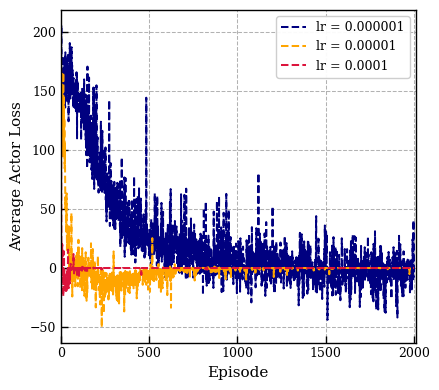

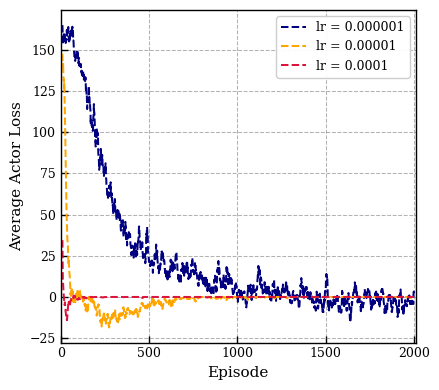

In [8]:
plot_node_lr_comparison(45)


## Figure 2 — 55 nodes

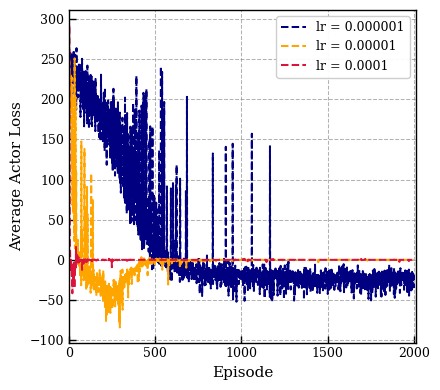

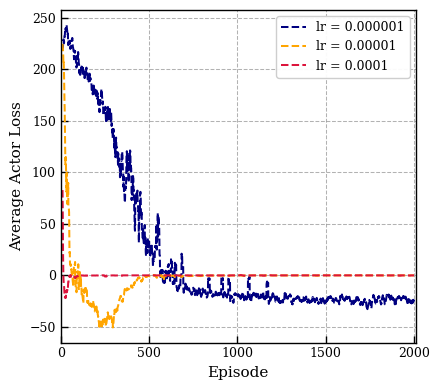

In [9]:
plot_node_lr_comparison(55)


## Figure 3 — 65 nodes

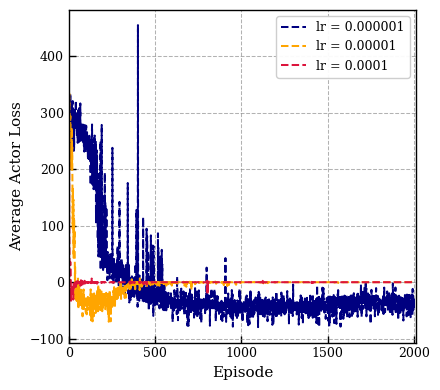

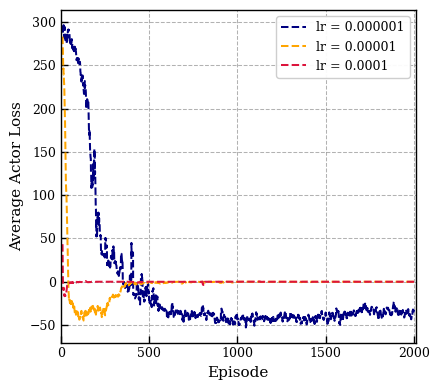

In [10]:
plot_node_lr_comparison(65)
